# I.0 — Data acquisition and audit

**Role E1 (data and repository).** This notebook gathers every data source used by the project, re-downloads the
market data from Binance's public archive instead of trusting copies, and audits the authors' P&D log against the
figures quoted by the brief and by the paper [A1] (Hu et al., SIGMOD 2023).

| Source | What it contains | How it is obtained here |
|---|---|---|
| `Data/Telegram/Labeled/PD_logs_cleaned.txt` | one row per (channel, pump): channel id, session id, coin, exchange, pair, timestamp | authors' file, read-only |
| Binance spot klines (1 h, 1 min) | OHLCV, quote volume, taker-buy volume, trade count | **downloaded** from `data.binance.vision` (monthly archives, cached) |
| `coinDate2Statistics_pred3d.json` | CoinGecko snapshot of each pump target 3 days before the pump | authors' file |
| `neg_coin_gecko_statistics.txt` | the same statistics for the non-target (candidate) coins | authors' file |
| `neg_binance_required_file_name.txt` | the (symbol, month) pairs the authors used as negatives | authors' file, defines the coin universe |
| `Data/Telegram/raw/*.pkl` | raw channel posts (Telethon dictionaries) | authors' files, used in II.D |

Every later notebook re-loads what it needs through `pnd_paper` (no notebook reads another notebook's output);
downloads go to a shared cache so they happen once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pnd_paper import settings
from pnd_paper.data import pd_log, binance, universe, coingecko
from pnd_paper.report import Reporter, md, show, close, SERIES

settings.seed_everything()
R = Reporter("I0_data_acquisition")
md(f"Run mode: **{'QUICK' if settings.QUICK else 'FULL'}** (set `PND_QUICK=0` for the full sizes).")

Run mode: **QUICK** (set `PND_QUICK=0` for the full sizes).

## 1. The P&D log

**Definition.** A *sample* is a row of the log, i.e. a pair (channel $h$, pump announcement). An *event*
$e=(h, c^\star, \tau)$ in the brief's notation is a pump of coin $c^\star$ announced by channel $h$ at time $\tau$.
Several channels often relay the **same** pump (same coin, same exchange, same minute); [A1] calls the set of
rows describing the same pump an *event* and reports 1 335 samples for 709 events.

We audit the figures quoted by the brief: 1 335 rows, 108 channels, 277 coins, 75 % of rows on Binance and 91 % with
a BTC quote.

In [2]:
log = pd_log.load_pd_log()
audit = pd.DataFrame({
    "brief": [1335, 108, 277, 0.75, 0.91],
    "paper [A1]": [1335, 108, 278, np.nan, np.nan],
    "observed": [len(log), log.channel_id.nunique(), log.coin.nunique(), (log.exchange == "binance").mean(), (log.pair == "BTC").mean()],
}, index=["rows (samples)", "channels", "coins", "share Binance", "share BTC pair"])
R.table(audit, "audit_vs_brief")
show(audit)

,brief,paper [A1],observed
rows (samples),1335,1335,1335
channels,108,108,108
coins,277,278,277
share Binance,0.75,nan,0.7513
share BTC pair,0.91,nan,0.9071


### From samples to events

Two rows belong to the same pump when they share the coin, the exchange and the announcement time up to a tolerance
$\delta$. Let $G_\delta$ be the graph whose vertices are rows and whose edges join rows with the same
(coin, exchange) and $|\tau_a-\tau_b|\le\delta$; events are the connected components of $G_\delta$. We report the
number of events for several $\delta$ to see which convention reproduces the paper's 709.

In [3]:
def count_events(df, delta):
    n = 0
    for _, g in df.sort_values("timestamp").groupby(["coin", "exchange"]):
        gaps = g.timestamp.diff() > delta
        n += 1 + int(gaps.sum())
    return n

deltas = {"same minute": pd.Timedelta(minutes=1), "1 hour": pd.Timedelta(hours=1), "12 hours": pd.Timedelta(hours=12),
          "1 day": pd.Timedelta(days=1), "3 days": pd.Timedelta(days=3)}
ev_counts = pd.DataFrame({"events": {k: count_events(log, d) for k, d in deltas.items()}})
ev_counts["Binance events"] = {k: count_events(log[log.exchange == "binance"], d) for k, d in deltas.items()}
R.table(ev_counts, "events_by_tolerance")
show(ev_counts)

,events,Binance events
same minute,779,516
1 hour,704,446
12 hours,698,440
1 day,691,437
3 days,680,430


The paper's modelling set keeps the Binance rows with a BTC quote (948 positive samples, §6.1). We keep the same
population and drop exact duplicates (same channel, same coin, same minute), which gives the **event table** used
by every Binance-based notebook.

In [4]:
ev = pd_log.binance_btc_events(log)
split_counts = ev.split.value_counts().reindex(["train", "valid", "test"])
md(f"Binance/BTC samples after de-duplication: **{len(ev)}** (paper: 948). "
   f"Split by the paper's dates (train $\\tau<$ 2021-01-19 $\\le$ valid $<$ 2021-05-10 $\\le$ test): "
   f"train = {split_counts['train']}, valid = {split_counts['valid']}, test = {split_counts['test']} "
   f"(paper: 648 / 100 / 200).")
R.table(ev.drop(columns=["channel_id"]), "binance_btc_events", index=False)

Binance/BTC samples after de-duplication: **981** (paper: 948). Split by the paper's dates (train $\tau<$ 2021-01-19 $\le$ valid $<$ 2021-05-10 $\le$ test): train = 655, valid = 100, test = 226 (paper: 648 / 100 / 200).

WindowsPath('C:/Users/Dr.Console/Desktop/Pump-and-Dump-Detection-on-Cryptocurrency-master/results/I0_data_acquisition/tables/binance_btc_events.csv')

## 2. Binance hourly klines

The coin universe $\mathcal U$ is the set of BTC-quoted symbols that the authors used as negatives
(`neg_binance_required_file_name.txt`) together with every pump target. For each symbol we download all monthly
hourly archives between November 2018 and February 2022 (the first month leaves room for the 30-day estimation
window of I.3). A missing archive (HTTP 404) means the symbol was not trading that month.

In [5]:
symbols = universe.universe(ev) + ["BTCUSDT"]
panels = binance.build_hourly_panel(symbols, universe.PANEL_START, universe.PANEL_END)
close_ = panels["close"]
rep = pd.read_csv(settings.CACHE / "panels" / "hourly" / "download_report.csv")
coverage = pd.DataFrame({
    "symbols requested": [len(symbols)],
    "symbols with data": [int(close_.notna().any().sum())],
    "monthly archives requested": [len(rep)],
    "archives found": [int(rep.found.sum())],
    "hours in panel": [len(close_)],
    "non-missing hourly bars": [int(close_.notna().sum().sum())],
})
R.table(coverage.T.rename(columns={0: "value"}), "hourly_coverage")
show(coverage.T.rename(columns={0: "value"}))

,value
symbols requested,503
symbols with data,390
monthly archives requested,20120
archives found,8531
hours in panel,29184
non-missing hourly bars,6093862


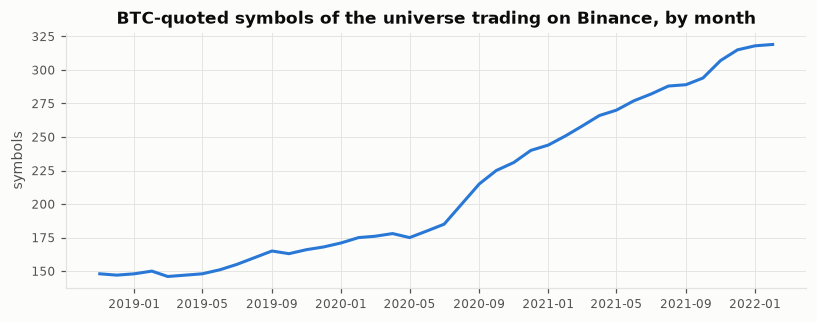

In [6]:
listed = close_.drop(columns="BTCUSDT").notna().resample("MS").max().sum(axis=1)
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(listed.index, listed.values, color=SERIES[0])
ax.set_title("BTC-quoted symbols of the universe trading on Binance, by month")
ax.set_ylabel("symbols")
R.fig(fig, "universe_size")
close(fig)

### Candidate sets

For event $i$ the candidate set $\mathcal C_i\subset\mathcal U$ holds the symbols trading during the 72 hours that
precede $\tau_i-1\,$h: the bar at $\tau_i-1\,$h exists and at least 60 of the previous 72 hourly bars exist. This is
the paper's "other eligible coins listed on Binance at the time of pump events". An event is usable when its
target belongs to $\mathcal C_i$.

Events whose target has hourly data at $\tau-1$h: **947 / 981**. Candidate set size $|\mathcal C_i|$: median 176, range [145, 314] (paper: about 206 negatives per positive on average). Positive ratio $1/|\mathcal C_i|$ averaged: 0.0052 (paper: 0.0048).

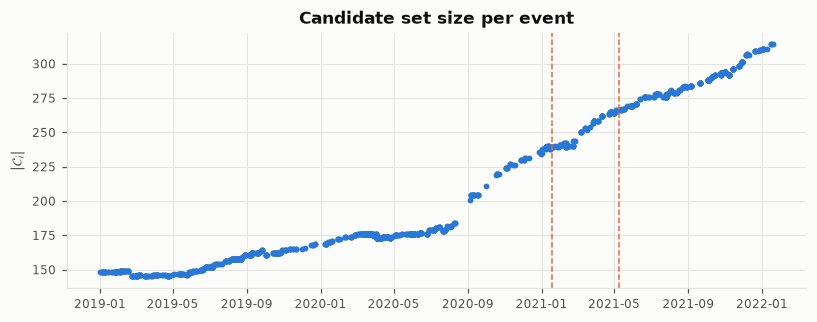

In [7]:
cands = universe.candidate_sets(ev, close_)
has_t = cands.groupby("event_id").label.max()
sizes = cands.groupby("event_id").size()
md(f"Events whose target has hourly data at $\\tau-1$h: **{int(has_t.sum())} / {len(ev)}**. "
   f"Candidate set size $|\\mathcal C_i|$: median {sizes.median():.0f}, range [{sizes.min()}, {sizes.max()}] "
   f"(paper: about 206 negatives per positive on average). Positive ratio "
   f"$1/|\\mathcal C_i|$ averaged: {(1 / sizes).mean():.4f} (paper: 0.0048).")
fig, ax = plt.subplots(figsize=(7.5, 3))
t = ev.set_index("event_id").timestamp.reindex(sizes.index)
ax.scatter(t, sizes.values, s=8, color=SERIES[0])
ax.set_title("Candidate set size per event")
ax.set_ylabel(r"$|\mathcal{C}_i|$")
for d in (settings.TRAIN_END, settings.VALID_END):
    ax.axvline(d, color=SERIES[1], lw=1, ls="--")
R.fig(fig, "candidate_set_size")
close(fig)

## 3. CoinGecko statistics

The authors queried CoinGecko's `/coins/{id}/history` endpoint three days before each pump. We check how many
targets and candidates are covered and the rate of missing values per field; missingness that differs between
targets and candidates would leak the label into a classifier, so it is examined here and handled in II.B.

In [8]:
gk = coingecko.load_all()
miss = gk.groupby("source")[coingecko.COLUMNS].apply(lambda d: d.isna().mean()).T
miss.columns = [f"missing share ({c})" for c in miss.columns]
R.table(miss, "coingecko_missingness")
show(miss, "{:.3f}")

,missing share (candidates),missing share (targets)
market_cap_usd,0.030,0.174
market_cap_btc,0.030,0.174
price_usd,0.000,0.049
price_btc,0.000,0.049
volume_usd,0.000,0.049
volume_btc,0.000,0.049
twitter_followers,0.156,0.214
reddit_subscribers,0.256,0.346
alexa_rank,0.035,0.149


## 4. Known data findings

The re-implementation of the authors' code (see `QUIRKS.md`) found two facts that matter for the analyses below:

* **Q37** — the shipped cleaned log differs from what the authors' cleaning script produces by 22 manual edits
  (exchange case, one coin, one dropped row). The log is nevertheless used as is: it is the authors' ground truth.
* **Binance audit** — on the first 100 rows, 99 archives exist and 93 of 99 pumps show a price spike of at least
  5 % within an hour of the announced time, so the timestamps are reliable at the hourly scale used here.

## 5. Summary

The data reproduce the brief's description of the log exactly. The paper's 709 events correspond to a de-duplication
of the 1 335 rows over relayed announcements; the Binance/BTC modelling population (981 de-duplicated rows here,
948 in the paper) is close to the paper's, and our split sizes differ from the paper's 648/100/200 because the paper
applies further filters that it does not describe.